# Experiment 2: Synthetic Heterogeneous Mixed-Variable Optimization

Evaluation of the **Generalized $(\mu, \lambda)$-Evolution Strategy** across synthetic benchmark functions combining all 6 decision variable types:
- **Real ($\mathbb{R}$)**: Continuous variables with Gaussian perturbation and log-normal self-adaptation $\sigma_{\text{real}}$
- **Count ($\mathbb{Z}$)**: Integer counts with Skellam mutation (Poisson difference) and log-normal self-adaptation $\lambda_{\text{count}}$
- **Binary ($\mathbb{B}$)**: Logit-mapped activation probabilities and logit-normal self-adaptation $\text{logit}_{\text{binary}}$
- **Categorical ($\mathbb{C}$)**: Softmax sampling over logit vectors and logit-normal self-adaptation $\text{logit}_{\text{cat}}$
- **Fuzzy ($\mathbb{F}$)**: Triangular control points $(a, b, c)$ with unit reflection, interlocking monotonicity ($a \le b \le c$), and log-normal self-adaptation $\sigma_{\text{fuzzy}}$
- **Circular ($\mathbb{S}^1$)**: Closed-order position steps ($\pm 1 \bmod k$) with forward logit self-adaptation $\text{logit}_{\text{circular}}$

In [2]:
import sys
import os
import numpy as np
import matplotlib.pyplot as plt

# Ensure workspace root is in sys.path
project_root = os.path.abspath("..") if os.path.exists("../src") else os.path.abspath(".")
if project_root not in sys.path:
    sys.path.insert(0, project_root)

from src.es_model.config import ESConfig
from src.es_model.engine import unpack_genome
from src.runners.custom_es import run as run_heterogeneous_es
from src.benchmarks.heterogeneous_functions import (
    HETEROGENEOUS_BENCHMARKS,
    heterogeneous_sphere,
    heterogeneous_rastrigin,
    heterogeneous_coupled,
)


## 1. Experiment Execution Configuration

The experiment can be toggled between **Phase 1 (Smoke Test)** and **Phase 2 (Production Run)**:

In [3]:
# Set SMOKE_RUN = True for quick validation (Phase 1), False for production results (Phase 2)
SMOKE_RUN = False

if SMOKE_RUN:
    MAX_EVALS = 1000
    N_SEEDS = 2
    print(">>> PHASE 1: Smoke Validation Mode (1,000 evaluations, 2 seeds)")
else:
    MAX_EVALS = 20000
    N_SEEDS = 10
    print(">>> PHASE 2: Production Run Mode (20,000 evaluations, 10 seeds)")

# Heterogeneous genome configuration testing all 6 variable types
CONFIG = ESConfig(
    mu=15,
    lam=100,
    n_real=5,
    n_count=3,
    n_binary=4,
    n_categorical=2,
    categorical_k=np.array([3, 4], dtype=np.int64),
    n_fuzzy=2,
    # n_circular=2,
    # circular_k=np.array([7, 12], dtype=np.int64),
    seed=42,
)

print(f"\nHeterogeneous ES Hyperparameters:")
print(f"  Survivors (mu): {CONFIG.mu}, Offspring (lambda): {CONFIG.lam}")
print(f"  Active Dimensions: Real={CONFIG.n_real}, Count={CONFIG.n_count}, Binary={CONFIG.n_binary}, Categorical={CONFIG.n_categorical}, Fuzzy={CONFIG.n_fuzzy} (x3 pts), Circular={CONFIG.n_circular}")
print(f"  Total Active Genome Dimensionality (n_total): {CONFIG.n_total}")


>>> PHASE 2: Production Run Mode (20,000 evaluations, 10 seeds)

Heterogeneous ES Hyperparameters:
  Survivors (mu): 15, Offspring (lambda): 100
  Active Dimensions: Real=5, Count=3, Binary=4, Categorical=2, Fuzzy=2 (x3 pts), Circular=0
  Total Active Genome Dimensionality (n_total): 20


## 2. Multi-Seed Optimization Execution

Executes the Heterogeneous ES on all 3 synthetic benchmarks with random seeds:

In [4]:
results = {}
SEEDS = [42 + i * 101 for i in range(N_SEEDS)] # Pseudo-random seeds

for bench_name, bench_info in HETEROGENEOUS_BENCHMARKS.items():
    print(f"\n==========================================")
    print(f" Running Benchmark: {bench_name}")
    print(f" {bench_info['description']}")
    print(f"==========================================")
    
    fn = bench_info["fn"]
    eval_fn = lambda ind_or_x, _fn=fn: _fn(ind_or_x, config=CONFIG)
    
    seed_traces = []
    for idx, seed in enumerate(SEEDS):
        trace = run_heterogeneous_es(
            fn=eval_fn,
            dim=CONFIG.n_real,
            bounds=(CONFIG.lower_bound_real, CONFIG.upper_bound_real),
            seed=seed,
            max_evals=MAX_EVALS,
            config=CONFIG,
        )
        seed_traces.append(trace)
        if (idx + 1) % max(1, N_SEEDS // 5) == 0 or idx == N_SEEDS - 1:
            print(f"  Seed {seed:5d} ({idx+1:2d}/{N_SEEDS}) | Final Best Fitness: {trace[-1]:.6e}")
            
    traces_arr = np.array(seed_traces)
    results[bench_name] = {
        "mean": np.mean(traces_arr, axis=0),
        "std": np.std(traces_arr, axis=0),
        "min": np.min(traces_arr, axis=0),
        "max": np.max(traces_arr, axis=0),
        "traces": traces_arr,
    }

# --- Save Convergence Traces to experiments/data/experiment_2/ ---
data_dir = os.path.join(project_root, "experiments", "data", "experiment_2")
os.makedirs(data_dir, exist_ok=True)

save_dict = {
    f"{bench_name}__traces": res["traces"]
    for bench_name, res in results.items()
}
save_dict["seeds"] = np.array(SEEDS, dtype=np.int64)

traces_path = os.path.join(data_dir, "exp2_traces.npz")
np.savez_compressed(traces_path, **save_dict)
print(f"\nSuccessfully saved experiment 2 traces to: {traces_path}")



 Running Benchmark: Heterogeneous_Sphere
 Convex separable mixed-variable benchmark across all 6 variable types
  Seed   143 ( 2/10) | Final Best Fitness: 1.861378e+00
  Seed   345 ( 4/10) | Final Best Fitness: 1.490204e-01
  Seed   547 ( 6/10) | Final Best Fitness: 5.734717e+00
  Seed   749 ( 8/10) | Final Best Fitness: 2.853285e+00
  Seed   951 (10/10) | Final Best Fitness: 9.760336e+00

 Running Benchmark: Heterogeneous_Rastrigin
 Multi-modal non-convex mixed-variable benchmark with cosine oscillations
  Seed   143 ( 2/10) | Final Best Fitness: 5.538320e+01
  Seed   345 ( 4/10) | Final Best Fitness: 5.504509e+01
  Seed   547 ( 6/10) | Final Best Fitness: 3.093225e+01
  Seed   749 ( 8/10) | Final Best Fitness: 5.818344e+01
  Seed   951 (10/10) | Final Best Fitness: 5.239975e+01

 Running Benchmark: Heterogeneous_Coupled
 Coupled mixed-variable benchmark with discrete regime switches
  Seed   143 ( 2/10) | Final Best Fitness: 4.177847e-01
  Seed   345 ( 4/10) | Final Best Fitness: 3.

## 3. Convergence Curves (Fitness vs. Evaluations)

Plots the mean fitness convergence curve with $\pm 1$ standard deviation across all random seeds:

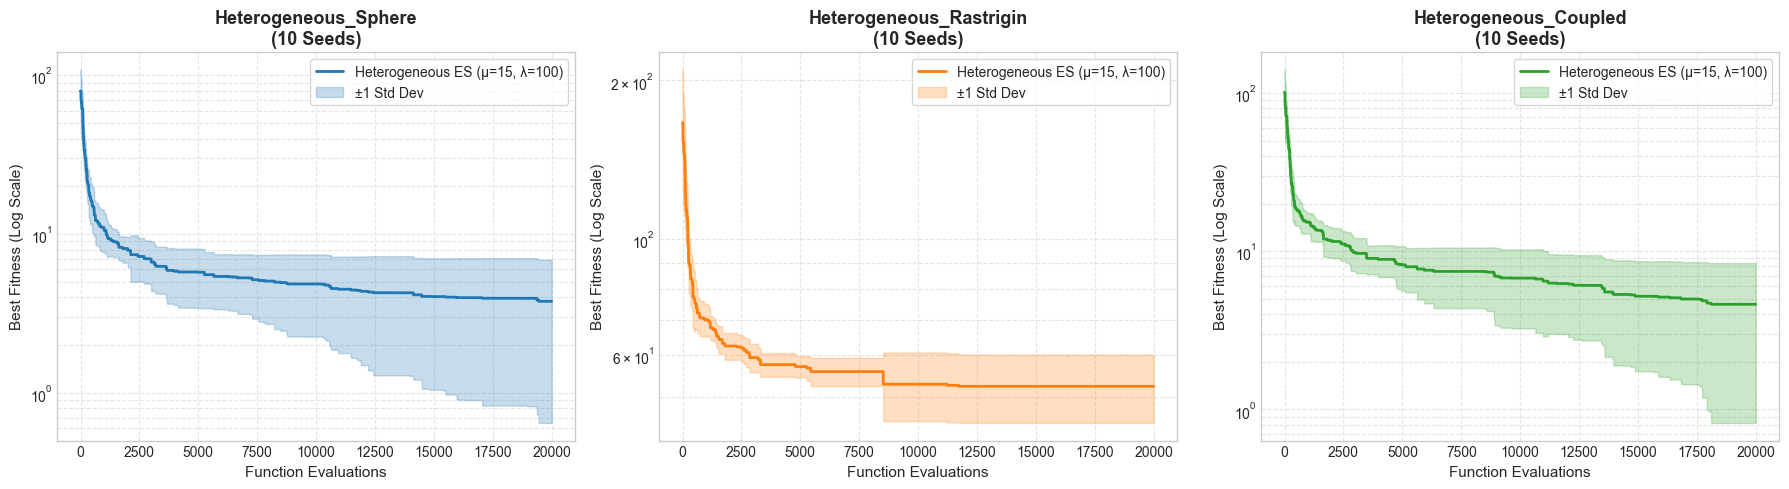

In [6]:
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=False)

bench_names = list(HETEROGENEOUS_BENCHMARKS.keys())
colors = ["#1f77b4", "#ff7f0e", "#2ca02c"]

for i, bench_name in enumerate(bench_names):
    ax = axes[i]
    res = results[bench_name]
    evals = np.arange(1, MAX_EVALS + 1)
    
    mean_trace = res["mean"]
    std_trace = res["std"]
    
    ax.plot(evals, mean_trace, color=colors[i], lw=2.0, label=f"Heterogeneous ES (μ={CONFIG.mu}, λ={CONFIG.lam})")
    ax.fill_between(evals, np.maximum(1e-12, mean_trace - std_trace), mean_trace + std_trace, color=colors[i], alpha=0.25, label="±1 Std Dev")
    
    ax.set_title(f"{bench_name}\n({N_SEEDS} Seeds)", fontsize=13, fontweight="bold")
    ax.set_xlabel("Function Evaluations", fontsize=11)
    ax.set_ylabel("Best Fitness (Log Scale)", fontsize=11)
    ax.set_yscale("log")
    ax.grid(True, which="both", ls="--", alpha=0.5)
    ax.legend(loc="upper right", frameon=True)

plt.tight_layout()
# plt.savefig("experiment_2_convergence.png", dpi=300, bbox_inches="tight")
plt.show()


## 4. Strategy Parameter Self-Adaptation Dynamics

Tracks the self-adaptation of strategy parameters across all 6 variable types on `Heterogeneous_Sphere`:

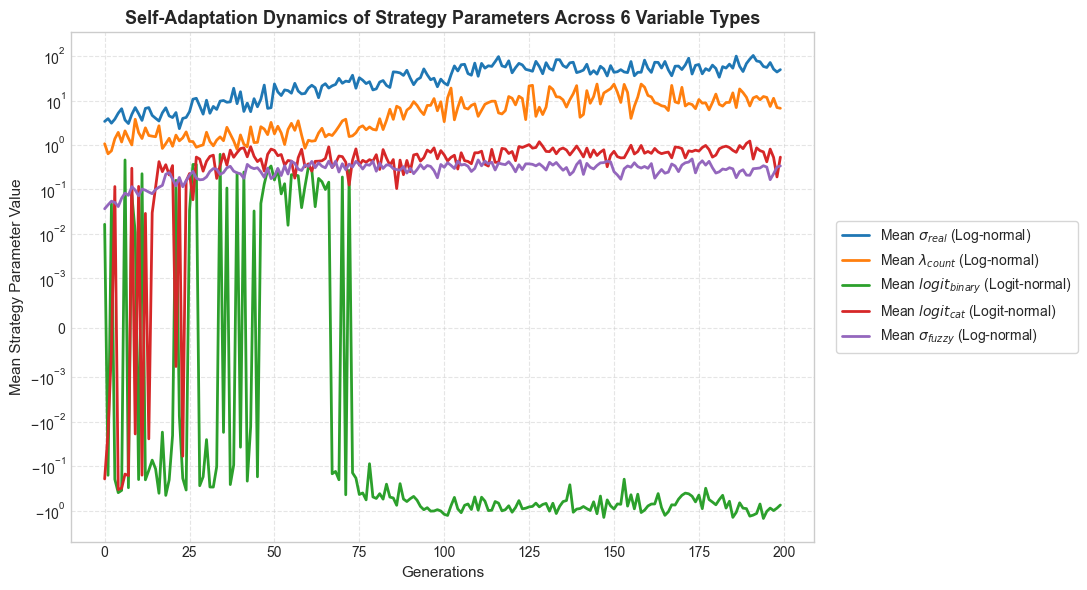

In [7]:
from src.es_model.engine import HeterogeneousES

tracking_es = HeterogeneousES(config=CONFIG, seed=42)
fn = HETEROGENEOUS_BENCHMARKS["Heterogeneous_Sphere"]["fn"]
eval_fn = lambda ind_or_x, _fn=fn: _fn(ind_or_x, config=CONFIG)

tracking_es.init_population(eval_fn)

gen_records = {
    "gen": [],
    "sigma_real": [],
    "lambda_count": [],
    "logit_binary": [],
    "logit_cat": [],
    "sigma_fuzzy": [],
    # "logit_circular": [],
}

n_generations = MAX_EVALS // CONFIG.lam

for g in range(n_generations):
    tracking_es.step(eval_fn)
    best_p = tracking_es.parents[0]
    
    gen_records["gen"].append(g)
    gen_records["sigma_real"].append(np.mean(best_p.sigma_real))
    gen_records["lambda_count"].append(np.mean(best_p.lambda_count))
    gen_records["logit_binary"].append(np.mean(best_p.logit_binary))
    gen_records["logit_cat"].append(np.mean(best_p.logit_cat))
    gen_records["sigma_fuzzy"].append(np.mean(best_p.sigma_fuzzy))
    # gen_records["logit_circular"].append(np.mean(best_p.logit_circular))

fig, ax = plt.subplots(figsize=(11, 6))

ax.plot(gen_records["gen"], gen_records["sigma_real"], label=r"Mean $\sigma_{real}$ (Log-normal)", lw=2.0)
ax.plot(gen_records["gen"], gen_records["lambda_count"], label=r"Mean $\lambda_{count}$ (Log-normal)", lw=2.0)
ax.plot(gen_records["gen"], gen_records["logit_binary"], label=r"Mean $logit_{binary}$ (Logit-normal)", lw=2.0)
ax.plot(gen_records["gen"], gen_records["logit_cat"], label=r"Mean $logit_{cat}$ (Logit-normal)", lw=2.0)
ax.plot(gen_records["gen"], gen_records["sigma_fuzzy"], label=r"Mean $\sigma_{fuzzy}$ (Log-normal)", lw=2.0)
# ax.plot(gen_records["gen"], gen_records["logit_circular"], label=r"Mean $logit_{circular}$ (Logit-normal)", lw=2.0)

ax.set_title("Self-Adaptation Dynamics of Strategy Parameters Across 6 Variable Types", fontsize=13, fontweight="bold")
ax.set_xlabel("Generations", fontsize=11)
ax.set_ylabel("Mean Strategy Parameter Value", fontsize=11)
ax.set_yscale("symlog", linthresh=1e-3)
ax.grid(True, which="both", ls="--", alpha=0.5)
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=True)

plt.tight_layout()
# plt.savefig("experiment_2_strategy_adaptation.png", dpi=300, bbox_inches="tight")
plt.show()

# --- Save Strategy Parameter Dynamics to experiments/data/experiment_2/ ---
dynamics_path = os.path.join(data_dir, "exp2_strategy_dynamics.npz")
np.savez_compressed(
    dynamics_path,
    **{k: np.array(v) for k, v in gen_records.items()}
)
print(f"Successfully saved strategy dynamics to: {dynamics_path}")


## 5. Statistical Results Summary Table

In [9]:
print("==========================================================================================")
print(f" EXPERIMENT 2 RESULTS SUMMARY ({N_SEEDS} Seeds | {MAX_EVALS} Max Evaluations)")
print("==========================================================================================")
print(f"{'Benchmark Function':<25} | {'Mean Best Fitness':<20} | {'Std Dev':<18} | {'Min (Best Run)':<18}")
print("-" * 88)

for bench_name, res in results.items():
    final_mean = res["mean"][-1]
    final_std = res["std"][-1]
    final_min = res["min"][-1]
    print(f"{bench_name:<25} | {final_mean:<20.6e} | {final_std:<18.6e} | {final_min:<18.6e}")

print("==========================================================================================")


 EXPERIMENT 2 RESULTS SUMMARY (10 Seeds | 20000 Max Evaluations)
Benchmark Function        | Mean Best Fitness    | Std Dev            | Min (Best Run)    
----------------------------------------------------------------------------------------
Heterogeneous_Sphere      | 3.777168e+00         | 3.129015e+00       | 1.439836e-01      
Heterogeneous_Rastrigin   | 5.230821e+01         | 7.759041e+00       | 3.093225e+01      
Heterogeneous_Coupled     | 4.615330e+00         | 3.793517e+00       | 4.177847e-01      
